# LexiLong: Overcoming the Quadratic Attention Bottleneck in Transformers using Linear Attention for Long-Document Classification

**Course:** Generative AI, CAC Project &nbsp;|&nbsp; **Date:** November 2026

---

## Abstract

Transformers read text by letting every token *attend* to every other token. This **self-attention** step is what makes them powerful, but its cost grows with the **square** of the text length, $O(N^2)$. Doubling the length of a document makes attention four times slower and four times more memory-hungry. In practice this is why most Transformer encoders cut documents off at 512 tokens.

In this project we:

1. **replace** softmax attention with **kernelised linear attention** (Katharopoulos et al., 2020), which reorders the computation so that the cost grows *linearly*, $O(N)$;
2. **train and benchmark** three otherwise identical models (softmax baseline, linear attention, and Linformer as a second comparison) on IMDB and Yelp reviews (Phase 3);
3. **deploy** the improved model as a *Long Customer Feedback Analyzer* web app (Phase 4).

| | Softmax (baseline) | Linear attention (ours) |
|---|---:|---:|
| IMDB test accuracy | 86.52% | 85.77% |
| Customer-review (Yelp) accuracy | 92.04% | **92.19%** |
| Inference at 4,096 tokens (batch 8) | 619 ms, 4.25 GB | **37 ms, 0.20 GB** (16.8× faster, 21× less memory) |
| Longest document it can process | 4,096 tokens (OOM at 8,192) | **16,384+ tokens** |
| Accuracy on long reviews when read in full instead of truncated | +3.1 points | **+3.5 points** |

Linear attention gives up less than one accuracy point (and none once more data is used) in exchange for an order-of-magnitude saving in time and memory on long documents.

## Contents

1. [Setup](#setup)
2. [Data: how long are real reviews?](#data)
3. [The models: three attention mechanisms in one encoder](#models)
4. [Correctness checks](#tests)
5. [Phase 3a: Training and classification quality](#training)
6. [Phase 3b: Efficiency scaling benchmark](#benchmark)
7. [Phase 3c: Does reading the whole document help?](#longdoc)
8. [Phase 4: Deployment, the Long Customer Feedback Analyzer](#phase4)
9. [Summary, conclusions and limitations](#summary)
10. [References](#refs)

**Code repository:** [https://github.com/Josh-Petrr/lexilong-linear-attention](https://github.com/Josh-Petrr/lexilong-linear-attention)

**How to run.** All outputs are already saved in this notebook, so it can be read without running anything. To re-run it, get the full project from GitHub, because the notebook loads `data.py`, the trained models in `checkpoints/` and the saved results in `results/` from its own folder:

```bash
git clone https://github.com/Josh-Petrr/lexilong-linear-attention.git
cd lexilong-linear-attention
pip install -r requirements.txt
jupyter notebook LexiLong.ipynb        # then: Kernel -> Restart & Run All
```

With the default settings, the notebook loads the trained checkpoints and saved results and runs in about 10 minutes (a CUDA GPU is needed for the speed tests). The datasets are downloaded and tokenised automatically on the first run. Set `RUN_TRAINING = True` in the setup cell to re-train all six models from scratch (about 1.5 hours on a 6 GB GPU).

<a id="setup"></a>
# 1. Setup

Imports, paths, reproducibility and the switch that controls the expensive training step. With `RUN_TRAINING = False` (the default) the notebook loads the trained checkpoints and saved results instead of recomputing them.

In [1]:
import os, sys, json, math, time, random, warnings
warnings.filterwarnings("ignore", message="IProgress not found")
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import Image, display
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

ROOT = os.path.abspath("")                    # this notebook lives in lexilong/
sys.path.insert(0, ROOT)
RESULTS = os.path.join(ROOT, "results")
CKPT_DIR = os.path.join(ROOT, "checkpoints")

# ---- Switch for the expensive step (False = load the saved checkpoints) ----
RUN_TRAINING = False        # ~1.5 h: re-train all 6 models (3 on IMDB, 3 on IMDB + Yelp)

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = torch.bfloat16 if device.type == "cuda" and torch.cuda.is_bf16_supported() else None

# One colour per model, used in every chart.
COLORS = {"softmax": "#2a78d6", "linear": "#eb6834", "linformer": "#1baf7a"}
LABELS = {"softmax": "Softmax (baseline)", "linear": "Linear attention (ours)", "linformer": "Linformer"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e4e3df", "font.size": 10})

print(f"PyTorch {torch.__version__} | device: {device}"
      + (f" ({torch.cuda.get_device_name()}, {torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GB)"
         if device.type == "cuda" else ""))

PyTorch 2.7.1+cu118 | device: cuda (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6.0 GB)


### 1.1 Numerical check of the Phase 2 identity

We compute the same kernel attention two ways on random data: the **quadratic** way (build the $N\times N$ matrix) and the **linear** way (build the $d\times d$ summary first). If the derivation is right, the outputs must be identical up to floating-point rounding, while the intermediate matrix is vastly smaller.

In [2]:
torch.manual_seed(0)
N, d = 4096, 32
Q, K, V = torch.randn(N, d), torch.randn(N, d), torch.randn(N, d)
phi = lambda x: F.elu(x) + 1                         # positive feature map

# Quadratic order: (phi(Q) phi(K)^T) V  -> builds an N x N matrix
A = phi(Q) @ phi(K).T                                # [N, N]
out_quadratic = (A @ V) / A.sum(dim=1, keepdim=True)

# Linear order: phi(Q) (phi(K)^T V)  -> builds a d x d summary
S_kv = phi(K).T @ V                                  # [d, d]  shared summary "box"
z = phi(K).sum(dim=0)                                # [d]     normaliser
out_linear = (phi(Q) @ S_kv) / (phi(Q) @ z)[:, None]

print(f"max |difference| between the two orders : {(out_quadratic - out_linear).abs().max():.2e}")
print(f"intermediate matrix, quadratic order     : {tuple(A.shape)} = {A.numel():>12,} numbers")
print(f"intermediate matrix, linear order        : {tuple(S_kv.shape)} = {S_kv.numel():>12,} numbers")
print(f"-> {A.numel() / S_kv.numel():,.0f}x smaller")

max |difference| between the two orders : 2.61e-08
intermediate matrix, quadratic order     : (4096, 4096) =   16,777,216 numbers
intermediate matrix, linear order        : (32, 32) =        1,024 numbers
-> 16,384x smaller


**Interpretation.** Both orders give the same answer (the difference is at the level of float32 rounding error), but the linear order only ever stores a $32\times32$ matrix instead of a $4096\times4096$ one, a 16,384× reduction. This is the entire idea of the project in four lines of code. Note that the identity holds for the kernel $\phi(q)^\top\phi(k)$, **not** for softmax: there is no way to split $\exp(q^\top k)$ like this, which is why we change the similarity function.

<a id="data"></a>
# 2. Data: how long are real reviews?

* **IMDB** (Maas et al., 2011): 50,000 movie reviews labelled positive / negative. 25,000 for training (of which 2,500 are held out for validation) and 25,000 for testing. Used for the controlled baseline-vs-improved comparison.
* **Yelp Polarity** (Zhang et al., 2015): business reviews about service, staff, delivery and refunds. A sample of 50,000 training and 10,000 test reviews is added for the deployment models, because our demo analyses *customer feedback*.

Text is split into tokens with the BERT WordPiece tokenizer (30,522-token vocabulary). `data.py` downloads the datasets once, tokenises them to 512 tokens and caches the result in `data_cache/`.

In [3]:
from data import load_data, get_tokenizer

train_ds, val_ds, test_sets, tokenizer, stats = load_data("imdb", max_len=512, seed=42)
print(f"train: {len(train_ds):,} | validation: {len(val_ds):,} | test: {len(test_sets['imdb']):,}")

# Full (untruncated) token lengths of the IMDB and Yelp test reviews, cached by data.py
imdb_lens = torch.load(os.path.join(ROOT, "data_cache", "imdb_512.pt"))["test"]["lens"].numpy()
yelp_lens = torch.load(os.path.join(ROOT, "data_cache", "yelp50k_512.pt"))["test"]["lens"].numpy()
for name, lens in [("IMDB", imdb_lens), ("Yelp", yelp_lens)]:
    print(f"{name:5s} test reviews: median {np.median(lens):.0f} tokens, 90th percentile {np.percentile(lens, 90):.0f}, "
          f"longest {lens.max():,}; {np.mean(lens > 512):.1%} are longer than 512 tokens")

# An example review, as the model sees it
ids, mask, label = test_sets["imdb"][0]
print("\nExample (label =", "positive" if label else "negative", "):")
print(tokenizer.decode(ids[mask][:80]) + " ...")

train: 22,500 | validation: 2,500 | test: 25,000


IMDB  test reviews: median 219 tokens, 90th percentile 565, longest 2,875; 12.3% are longer than 512 tokens
Yelp  test reviews: median 128 tokens, 90th percentile 367, longest 1,436; 4.1% are longer than 512 tokens

Example (label = negative ):
[CLS] i love sci - fi and am willing to put up with a lot. sci - fi movies / tv are usually underfunded, under - appreciated and misunderstood. i tried to like this, i really did, but it is to good tv sci - fi as babylon 5 is to star trek ( the original ). silly prosthetics, cheap cardboard sets, stilted dialogues, c ...


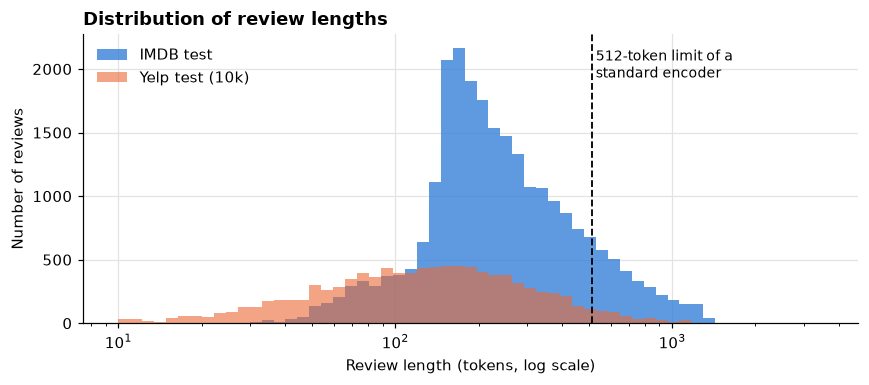

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.logspace(np.log10(10), np.log10(3500), 60)
ax.hist(imdb_lens, bins=bins, color="#2a78d6", alpha=0.75, label="IMDB test")
ax.hist(yelp_lens, bins=bins, color="#eb6834", alpha=0.6, label="Yelp test (10k)")
ax.axvline(512, color="black", ls="--", lw=1.2)
ax.text(530, ax.get_ylim()[1] * 0.85, "512-token limit of a\nstandard encoder", fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("Review length (tokens, log scale)"); ax.set_ylabel("Number of reviews")
ax.set_title("Distribution of review lengths", loc="left", fontweight="bold"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**Interpretation.** Most reviews are a few hundred tokens long, but there is a long tail: about **12% of IMDB test reviews (3,086 documents) are longer than 512 tokens**, and some run to well over 2,000. A standard 512-token Transformer has to throw away the end of exactly these documents, which are often the most detailed ones. Section 9 measures what that truncation costs.

<a id="models"></a>
# 3. The models: three attention mechanisms in one encoder

To make the comparison fair, all three models share **exactly the same encoder**. Only the attention module is swapped. Any difference in speed, memory or accuracy can therefore be attributed to attention alone.

### 3.1 The three attention modules

All modules take token vectors `x` of shape `[batch B, length N, width D]` and a padding mask, and return the same shape. The code below is identical to `models/attention.py`.

In [5]:
class _MultiHeadBase(nn.Module):
    """Shared plumbing: project x to queries/keys/values, split into heads, merge back."""
    def __init__(self, d_model, n_heads, dropout=0.1):
        super().__init__()
        assert d_model % n_heads == 0
        self.d_model, self.n_heads, self.d_head = d_model, n_heads, d_model // n_heads
        self.qkv = nn.Linear(d_model, 3 * d_model)      # one matmul gives Q, K and V
        self.out = nn.Linear(d_model, d_model)
        self.dropout = nn.Dropout(dropout)

    def _split(self, x):                                 # [B,N,3D] -> 3 x [B,H,N,Dh]
        B, N, _ = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        shape = (B, N, self.n_heads, self.d_head)
        return (t.view(shape).transpose(1, 2) for t in (q, k, v))

    def _merge(self, x):                                 # [B,H,N,Dh] -> [B,N,D]
        B, H, N, Dh = x.shape
        return self.out(x.transpose(1, 2).reshape(B, N, H * Dh))


class SoftmaxAttention(_MultiHeadBase):
    """BASELINE - standard attention. Builds the full N x N score matrix: O(N^2) time and memory."""
    def forward(self, x, mask=None):
        q, k, v = self._split(x)
        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.d_head)   # [B,H,N,N]  <- the bottleneck
        if mask is not None:                                                     # padding gets zero weight
            scores = scores.masked_fill(~mask[:, None, None, :], float("-inf"))
        attn = self.dropout(torch.softmax(scores, dim=-1))
        return self._merge(torch.matmul(attn, v))


class LinearAttention(_MultiHeadBase):
    """PROPOSED - kernelised linear attention, phi(x) = elu(x) + 1. O(N d^2) time, no N x N matrix."""
    def __init__(self, d_model, n_heads, dropout=0.1, eps=1e-6):
        super().__init__(d_model, n_heads, dropout)
        self.eps = eps                                   # avoids division by zero

    @staticmethod
    def feature_map(x):
        return F.elu(x) + 1.0                            # always > 0, like softmax weights

    def forward(self, x, mask=None):
        q, k, v = self._split(x)
        orig_dtype = q.dtype
        q, k, v = q.float(), k.float(), v.float()        # sums over N can overflow in 16-bit -> use fp32
        q, k = self.feature_map(q), self.feature_map(k)
        if mask is not None:                             # padding must not enter the shared summary
            m = mask[:, None, :, None].to(k.dtype)
            k, v = k * m, v * m
        kv = torch.einsum("bhnd,bhne->bhde", k, v)                         # S_KV: [B,H,Dh,Dh], independent of N
        k_sum = k.sum(dim=2)                                               # z:    [B,H,Dh]
        z = 1.0 / (torch.einsum("bhnd,bhd->bhn", q, k_sum) + self.eps)     # 1 / (phi(q_i)^T z)
        out = torch.einsum("bhnd,bhde,bhn->bhne", q, kv, z)                # phi(q_i)^T S_KV / (phi(q_i)^T z)
        return self._merge(self.dropout(out).to(orig_dtype))


class LinformerAttention(_MultiHeadBase):
    """COMPARISON - Linformer: compress the N keys/values to k=128 rows with learned E, F. O(N k)."""
    def __init__(self, d_model, n_heads, dropout=0.1, max_len=8192, k_proj=128):
        super().__init__(d_model, n_heads, dropout)
        self.E = nn.Parameter(torch.randn(max_len, k_proj) / math.sqrt(k_proj))   # fixed maximum length!
        self.F = nn.Parameter(torch.randn(max_len, k_proj) / math.sqrt(k_proj))

    def forward(self, x, mask=None):
        q, k, v = self._split(x)
        N = x.shape[1]
        if N > self.E.shape[0]:
            raise ValueError(f"Linformer max_len={self.E.shape[0]} < sequence length {N}")
        if mask is not None:
            m = mask[:, None, :, None].to(k.dtype)
            k, v = k * m, v * m
        k = torch.einsum("bhnd,nk->bhkd", k, self.E[:N])                         # [B,H,k,Dh]
        v = torch.einsum("bhnd,nk->bhkd", v, self.F[:N])
        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.d_head)   # [B,H,N,k]
        attn = self.dropout(torch.softmax(scores, dim=-1))
        return self._merge(torch.matmul(attn, v))


def build_attention(kind, d_model, n_heads, dropout=0.1, max_len=8192):
    if kind == "softmax":   return SoftmaxAttention(d_model, n_heads, dropout)
    if kind == "linear":    return LinearAttention(d_model, n_heads, dropout)
    if kind == "linformer": return LinformerAttention(d_model, n_heads, dropout, max_len=max_len)
    raise ValueError(kind)

### 3.2 The shared encoder classifier

A small pre-LayerNorm Transformer encoder (code identical to `models/encoder.py`):

* token embedding + **sinusoidal positional encoding** (computed on the fly, so any length works);
* **4 encoder blocks**, each `x + Attention(LayerNorm(x))` then `x + FeedForward(LayerNorm(x))`;
* width $d_{model}=128$, 4 heads of 32 dimensions, feed-forward width 512;
* **masked mean pooling** (average of the real tokens' vectors) and a linear layer giving 2 class scores (negative / positive).

In [6]:
class SinusoidalPositionalEncoding(nn.Module):
    """Fixed sin/cos position signal (Vaswani et al., 2017). No parameters, works for any length."""
    def __init__(self, d_model):
        super().__init__()
        self.d_model = d_model

    def forward(self, x):
        N, D = x.shape[1], self.d_model
        pos = torch.arange(N, device=x.device, dtype=torch.float32).unsqueeze(1)
        div = torch.exp(torch.arange(0, D, 2, device=x.device, dtype=torch.float32) * (-math.log(10000.0) / D))
        pe = torch.zeros(N, D, device=x.device)
        pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
        return x + pe.unsqueeze(0).to(x.dtype)


class EncoderBlock(nn.Module):
    """Pre-LN Transformer block. The attention module is the ONLY part that differs between models."""
    def __init__(self, attn_type, d_model, n_heads, d_ff, dropout, max_len):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = build_attention(attn_type, d_model, n_heads, dropout, max_len)
        self.ln2 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Dropout(dropout), nn.Linear(d_ff, d_model))
        self.drop = nn.Dropout(dropout)

    def forward(self, x, mask):
        x = x + self.drop(self.attn(self.ln1(x), mask))
        return x + self.drop(self.ffn(self.ln2(x)))


class LexiLongClassifier(nn.Module):
    def __init__(self, vocab_size, attn_type="softmax", d_model=128, n_heads=4, n_layers=4, d_ff=512,
                 n_classes=2, dropout=0.1, max_len=8192, pad_id=0):
        super().__init__()
        self.config = dict(vocab_size=vocab_size, attn_type=attn_type, d_model=d_model, n_heads=n_heads,
                           n_layers=n_layers, d_ff=d_ff, n_classes=n_classes, dropout=dropout,
                           max_len=max_len, pad_id=pad_id)
        self.embed = nn.Embedding(vocab_size, d_model, padding_idx=pad_id)
        self.pos = SinusoidalPositionalEncoding(d_model)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([EncoderBlock(attn_type, d_model, n_heads, d_ff, dropout, max_len)
                                     for _ in range(n_layers)])
        self.ln = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, n_classes)

    def forward(self, input_ids, attention_mask=None):
        if attention_mask is None:
            attention_mask = torch.ones_like(input_ids, dtype=torch.bool)
        mask = attention_mask.bool()
        x = self.drop(self.pos(self.embed(input_ids) * math.sqrt(self.config["d_model"])))
        for blk in self.blocks:
            x = blk(x, mask)
        x = self.ln(x)
        m = mask.unsqueeze(-1).to(x.dtype)                       # masked mean pooling over real tokens
        pooled = (x * m).sum(1) / m.sum(1).clamp(min=1.0)
        return self.head(pooled)                                 # [B, 2] class scores

    @classmethod
    def from_checkpoint(cls, path, map_location="cpu"):
        ckpt = torch.load(path, map_location=map_location, weights_only=False)
        model = cls(**ckpt["config"])
        model.load_state_dict(ckpt["state_dict"])
        return model

In [7]:
rows = []
for attn in ("softmax", "linear", "linformer"):
    m = LexiLongClassifier(tokenizer.vocab_size, attn_type=attn, max_len=512, pad_id=tokenizer.pad_token_id)
    attn_params = sum(p.numel() for b in m.blocks for p in b.attn.parameters())
    rows.append({"Model": LABELS[attn], "Total parameters": f"{sum(p.numel() for p in m.parameters()):,}",
                 "Attention parameters": f"{attn_params:,}"})
pd.DataFrame(rows)

,Model,Total parameters,Attention parameters
0,Softmax (baseline),"4,700,418","264,192"
1,Linear attention (ours),"4,700,418","264,192"
2,Linformer,"5,224,706","788,480"


**Interpretation.** Softmax and linear attention have *exactly* the same number of parameters (4.70 M): linear attention is a change in *how* attention is computed, not in model size. Linformer adds about 0.5 M parameters for its position-specific compression matrices $E$ and $F$ (2 × 512 × 128 per layer), which, as we will see, makes it more prone to overfitting.

<a id="tests"></a>
# 4. Correctness checks

Before training, we check two properties of the implementation:

1. **Padding invariance.** In a batch, short reviews are filled with padding tokens. Adding padding must not change the model's output.
2. **Linear attention really computes the kernel attention formula.** The fast einsum implementation must match the slow, explicit $N\times N$ version of the same formula.

In [8]:
torch.manual_seed(0)
print("1) Padding invariance (output change when 24 padding tokens are appended)")
for attn in ("softmax", "linear", "linformer"):
    model = LexiLongClassifier(1000, attn_type=attn, max_len=512).eval()
    ids = torch.randint(1, 1000, (2, 40))
    padded = torch.cat([ids, torch.zeros(2, 24, dtype=torch.long)], dim=1)
    mask = torch.cat([torch.ones(2, 40), torch.zeros(2, 24)], dim=1).bool()
    with torch.no_grad():
        diff = (model(ids) - model(padded, mask)).abs().max().item()
    print(f"   {LABELS[attn]:26s} max |change| = {diff:.1e}  ->  {'PASS' if diff < 1e-5 else 'FAIL'}")

print("\n2) Fast linear attention vs. explicit N x N kernel attention")
la = LinearAttention(128, 4, dropout=0.0).eval()
x = torch.randn(2, 300, 128)
with torch.no_grad():
    fast = la(x)
    q, k, v = la._split(x)
    q, k = la.feature_map(q), la.feature_map(k)
    weights = q @ k.transpose(-2, -1)                            # [B,H,N,N] explicit similarity table
    slow = la._merge((weights / weights.sum(-1, keepdim=True)) @ v)
print(f"   max |fast - explicit| = {(fast - slow).abs().max():.1e}  ->  {'PASS' if torch.allclose(fast, slow, atol=1e-5) else 'FAIL'}")

1) Padding invariance (output change when 24 padding tokens are appended)
   Softmax (baseline)         max |change| = 1.9e-08  ->  PASS
   Linear attention (ours)    max |change| = 1.5e-08  ->  PASS
   Linformer                  max |change| = 3.0e-08  ->  PASS

2) Fast linear attention vs. explicit N x N kernel attention
   max |fast - explicit| = 6.0e-08  ->  PASS


**Interpretation.** All three attention modules ignore padding (changes of order $10^{-8}$, i.e. floating-point noise), and the fast linear-attention implementation is numerically the same as the textbook formula it replaces. Any accuracy difference we see later is therefore due to the change of *similarity function* (elu + 1 instead of softmax), not to a bug.

<a id="training"></a>
# 5. Phase 3a: Training and classification quality

### 5.1 Training procedure

Every model is trained with identical settings:

| Setting | Value |
|---|---|
| Max length during training | 512 tokens |
| Optimiser | AdamW, learning rate 5e-4, weight decay 0.01 |
| Schedule | One-cycle (warm up for 10% of steps, then anneal) |
| Batch size | 32 |
| Precision | bf16 mixed precision (linear-attention sums kept in fp32) |
| Gradient clipping | 1.0 |
| Epochs | 5 (IMDB) / 4 (IMDB + Yelp) |
| Model selection | Checkpoint with the best validation accuracy is evaluated on the test set |
| Seed | 42 |

The training loop below only runs if `RUN_TRAINING = True`; otherwise the saved checkpoints and metrics (produced by exactly this code) are loaded.

In [9]:
from torch.utils.data import DataLoader

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    preds, labels = [], []
    for ids, mask, y in loader:
        with torch.autocast(device_type=device.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE is not None):
            logits = model(ids.to(device), mask.to(device))
        preds.append(logits.argmax(-1).cpu()); labels.append(y)
    preds, labels = torch.cat(preds).numpy(), torch.cat(labels).numpy()
    return accuracy_score(labels, preds), f1_score(labels, preds), preds, labels


def train_model(attn, dataset="imdb", epochs=5, lr=5e-4, batch_size=32):
    set_seed(42)
    tr, va, tests, tok, _ = load_data(dataset, 512, seed=42)
    train_dl = DataLoader(tr, batch_size=batch_size, shuffle=True)
    val_dl = DataLoader(va, batch_size=64)
    model = LexiLongClassifier(tok.vocab_size, attn_type=attn, max_len=512, pad_id=tok.pad_token_id).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * len(train_dl), pct_start=0.1)
    loss_fn = nn.CrossEntropyLoss()
    tag = attn if dataset == "imdb" else f"{dataset}_{attn}"
    path, best, history = os.path.join(CKPT_DIR, f"{tag}.pt"), -1, []
    for epoch in range(1, epochs + 1):
        model.train(); t0, running = time.time(), 0.0
        for ids, mask, y in train_dl:
            ids, mask, y = ids.to(device), mask.to(device), y.to(device)
            with torch.autocast(device_type=device.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE is not None):
                loss = loss_fn(model(ids, mask), y)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step()
            running += loss.item()
        val_acc, val_f1, _, _ = evaluate(model, val_dl)
        history.append(dict(epoch=epoch, train_loss=running / len(train_dl), val_acc=val_acc,
                            val_f1=val_f1, epoch_time_s=time.time() - t0))
        print(f"[{tag}] epoch {epoch}: loss {history[-1]['train_loss']:.4f} | val acc {val_acc:.4f}")
        if val_acc > best:
            best = val_acc
            torch.save({"config": model.config, "state_dict": model.state_dict()}, path)
    return history


if RUN_TRAINING:
    for attn in ("softmax", "linear", "linformer"):
        train_model(attn, "imdb", epochs=5)
        train_model(attn, "feedback", epochs=4)
else:
    print("RUN_TRAINING = False -> using the saved checkpoints in checkpoints/ and metrics in results/")

RUN_TRAINING = False -> using the saved checkpoints in checkpoints/ and metrics in results/


### 5.2 Results on IMDB (controlled benchmark)

We load the saved training metrics and also **re-evaluate every saved checkpoint on the full 25,000-review test set** right here, so the numbers are reproduced live rather than copied.

In [10]:
def load_metrics(tag):
    with open(os.path.join(RESULTS, f"metrics_{tag}.json")) as f:
        return json.load(f)

metrics = {a: load_metrics(a) for a in ("softmax", "linear", "linformer")}
imdb_test_dl = DataLoader(test_sets["imdb"], batch_size=64)

rows, imdb_preds = [], {}
for attn, m in metrics.items():
    model = LexiLongClassifier.from_checkpoint(os.path.join(CKPT_DIR, f"{attn}.pt")).to(device)
    acc, f1, preds, labels = evaluate(model, imdb_test_dl)
    imdb_preds[attn] = (preds, labels)
    rows.append({"Model": LABELS[attn],
                 "Test accuracy (live)": f"{acc:.2%}", "Test F1 (live)": f"{f1:.2%}",
                 "Best val. accuracy": f"{m['best_val_acc']:.2%}",
                 "Median time / epoch (s)": round(float(np.median([h['epoch_time_s'] for h in m['history']])), 1),
                 "Peak training memory (MB)": round(m["peak_train_mem_mb"])})
    del model
torch.cuda.empty_cache()
imdb_table = pd.DataFrame(rows).set_index("Model")
imdb_table

,Test accuracy (live),Test F1 (live),Best val. accuracy,Median time / epoch (s),Peak training memory (MB)
Model,,,,,
Softmax (baseline),86.52%,86.44%,87.60%,121.0,1543
Linear attention (ours),85.77%,85.59%,87.24%,36.0,560
Linformer,80.20%,80.53%,81.68%,37.7,694


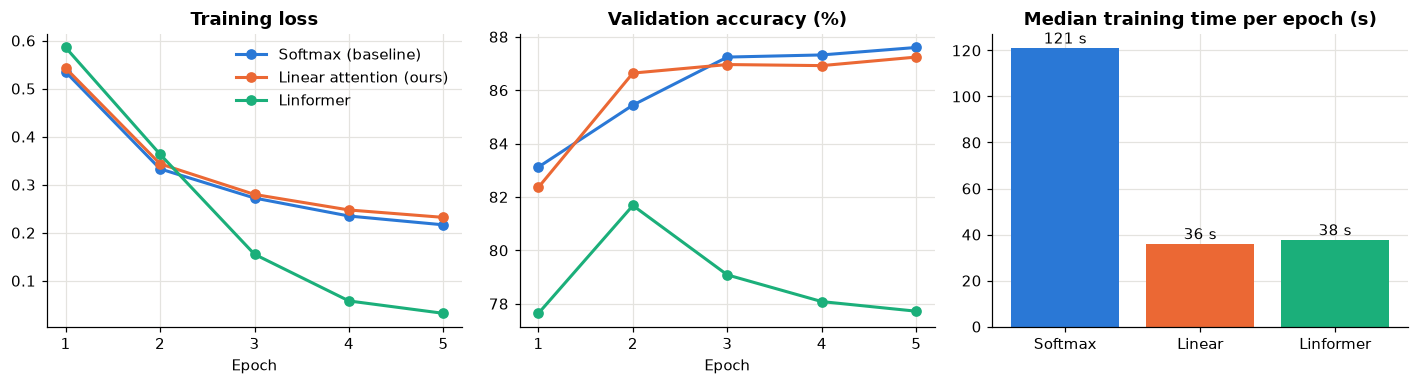

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for attn, m in metrics.items():
    h = pd.DataFrame(m["history"])
    kw = dict(color=COLORS[attn], marker="o", lw=2, label=LABELS[attn])
    axes[0].plot(h.epoch, h.train_loss, **kw)
    axes[1].plot(h.epoch, h.val_acc * 100, **kw)
t = imdb_table["Median time / epoch (s)"]
axes[2].bar(range(3), t.values, color=[COLORS[a] for a in metrics])
axes[2].set_xticks(range(3)); axes[2].set_xticklabels(["Softmax", "Linear", "Linformer"])
for i, v in enumerate(t.values):
    axes[2].text(i, v + 2, f"{v:.0f} s", ha="center")
axes[0].set(title="Training loss", xlabel="Epoch", xticks=range(1, 6)); axes[1].set(title="Validation accuracy (%)", xlabel="Epoch", xticks=range(1, 6))
axes[2].set(title="Median training time per epoch (s)")
axes[0].legend(frameon=False)
for ax in axes: ax.title.set_fontweight("bold")
plt.tight_layout(); plt.show()

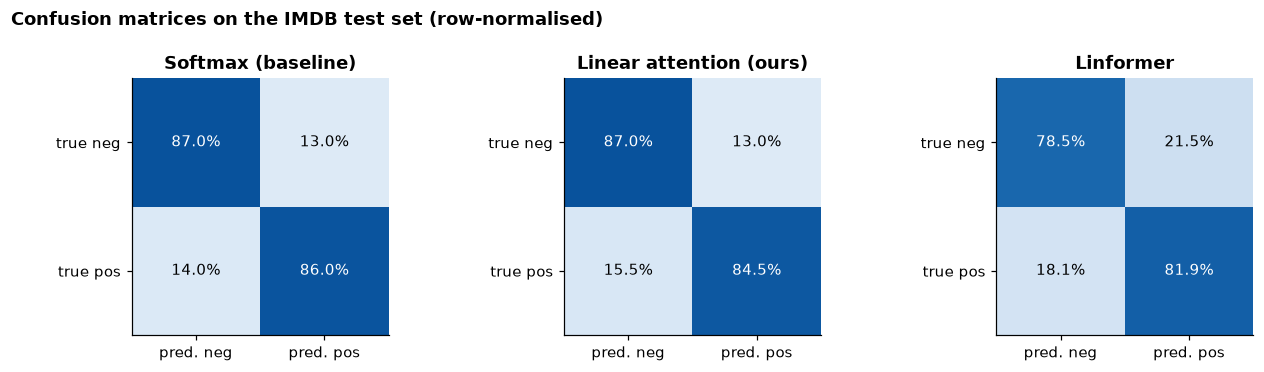

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, attn in zip(axes, ("softmax", "linear", "linformer")):
    preds, labels = imdb_preds[attn]
    cm = confusion_matrix(labels, preds, normalize="true") * 100
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=100)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:.1f}%", ha="center", va="center", color="white" if cm[i, j] > 50 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["pred. neg", "pred. pos"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["true neg", "true pos"])
    ax.set_title(LABELS[attn], fontweight="bold"); ax.grid(False)
plt.suptitle("Confusion matrices on the IMDB test set (row-normalised)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

**Interpretation.**

* **Accuracy.** Linear attention reaches **85.8%** against softmax's **86.5%**, a gap of only **0.75 points**. This is inside the 1–2 point budget of hypothesis **H2**. The confusion matrices show both models make balanced errors (they are not biased towards one class).
* **Speed and memory.** Even at the *short* training length of 512 tokens, linear attention trains **about 3.4× faster per epoch and with about 2.8× less GPU memory**. The advantage will grow with length (Section 8).
* **Linformer overfits.** Its training loss falls fastest (it memorises the training set) but its validation accuracy peaks at epoch 2 and then declines, ending **6 points below softmax**. The extra 0.5 M position-specific parameters make it easy to memorise and hard to generalise.
* **Why the small gap?** The elu + 1 kernel produces *smoother* attention than softmax: it cannot concentrate almost all of its weight on one token the way $\exp$ can. For sentiment, which depends on the overall tone of a review, this costs very little.

### 5.3 Deployment models: IMDB + 50k Yelp customer reviews

The demo analyses customer complaints, not film reviews. The IMDB-only models labelled the complaint *"The delivery was two weeks late, the package was damaged and customer service never replied to my emails. I want a refund."* as **99% positive**: film reviews simply do not contain the vocabulary of refunds and support calls (**domain shift**). We therefore trained a second set of models on IMDB + 50,000 Yelp business reviews and evaluated them on both test sets.

In [13]:
_, _, fb_tests, _, _ = load_data("feedback", 512, seed=42)
rows = []
for attn in ("softmax", "linear", "linformer"):
    m = load_metrics(f"feedback_{attn}")
    model = LexiLongClassifier.from_checkpoint(os.path.join(CKPT_DIR, f"feedback_{attn}.pt")).to(device)
    row = {"Model": LABELS[attn]}
    for name, ds in fb_tests.items():
        acc, f1, _, _ = evaluate(model, DataLoader(ds, batch_size=64))
        row[f"{name.upper()} accuracy"] = f"{acc:.2%}"
        row[f"{name.upper()} F1"] = f"{f1:.2%}"
    row["Median time / epoch (s)"] = round(float(np.median([h["epoch_time_s"] for h in m["history"]])), 1)
    rows.append(row)
    del model
torch.cuda.empty_cache()
pd.DataFrame(rows).set_index("Model")

,IMDB accuracy,IMDB F1,YELP accuracy,YELP F1,Median time / epoch (s)
Model,,,,,
Softmax (baseline),86.37%,86.25%,92.04%,91.93%,274.5
Linear attention (ours),86.22%,86.03%,92.19%,92.09%,97.7
Linformer,83.13%,83.91%,90.16%,90.37%,126.5


**Interpretation.** With more (and more varied) training data **the accuracy gap disappears**: linear attention is 0.15 points *better* than softmax on Yelp customer reviews and 0.15 points lower on IMDB, a statistical tie, while training **2.8× faster per epoch**. Linformer again trails by 2–3 points. These deployment models are the ones used in the Phase 4 app.

*(Linformer's third deployment epoch spanned a laptop sleep, so all epoch times are reported as medians.)*

<a id="benchmark"></a>
# 6. Phase 3b: Efficiency scaling benchmark (hypothesis H1)

The real test is how cost grows with document length. We feed random token sequences of length $N$ (batch of 8) through freshly initialised models (weights do not affect speed) and measure:

* **latency** per batch with CUDA events (3 warm-up and 10 timed iterations);
* **peak GPU memory**;
* whether the GPU runs **out of memory (OOM)**, which is recorded as a result, not a crash.

### 6.1 A quick live run

The benchmarking function is defined below. We run a small sweep live (inference only, up to 4,096 tokens) to demonstrate it; the full sweep up to 16,384 tokens, including training steps, is loaded from `results/benchmark.csv` in the next step.

*Note: absolute timings on a laptop GPU vary from run to run (clock boosting, background load), so the live latencies can differ from the saved sweep. Peak memory is deterministic and should match exactly.*

In [14]:
def bench_one(attn, seq_len, batch_size=8, mode="infer", warmup=3, iters=10, vocab=30522):
    model = LexiLongClassifier(vocab, attn_type=attn, max_len=max(seq_len, 512)).to(device)
    model.train(mode == "train")
    ids = torch.randint(1, vocab, (batch_size, seq_len), device=device)
    mask = torch.ones_like(ids, dtype=torch.bool)

    def step():
        if mode == "train":
            model.zero_grad(set_to_none=True); model(ids, mask).sum().backward()
        else:
            with torch.no_grad(): model(ids, mask)
    try:
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
        for _ in range(warmup): step()
        torch.cuda.synchronize()
        start, end = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
        start.record()
        for _ in range(iters): step()
        end.record(); torch.cuda.synchronize()
        return dict(latency_ms=start.elapsed_time(end) / iters, peak_mem_mb=torch.cuda.max_memory_allocated() / 2**20, oom=False)
    except torch.OutOfMemoryError:
        return dict(latency_ms=np.nan, peak_mem_mb=np.nan, oom=True)
    finally:
        del model, ids, mask; torch.cuda.empty_cache()


if device.type == "cuda":
    for _ in range(3):                  # wake the laptop GPU from its idle clock speed first
        bench_one("linear", 2048, iters=20)
    live = []
    for attn in ("softmax", "linear"):
        for n in (512, 1024, 2048, 4096):
            r = bench_one(attn, n, warmup=5, iters=20)
            live.append({"Model": LABELS[attn], "N": n, **r})
    live = pd.DataFrame(live)
    display(live.pivot(index="Model", columns="N", values="latency_ms").round(1).rename_axis("Latency (ms) / N"))
    display(live.pivot(index="Model", columns="N", values="peak_mem_mb").round(0).rename_axis("Peak memory (MB) / N"))
else:
    print("No GPU: skipping the live benchmark.")

N,512,1024,2048,4096
Latency (ms) / N,,,,
Linear attention (ours),5.6,10.1,19.7,56.2
Softmax (baseline),18.3,82.4,270.6,2810.0


N,512,1024,2048,4096
Peak memory (MB) / N,,,,
Linear attention (ours),48.0,70.0,114.0,202.0
Softmax (baseline),107.0,315.0,1115.0,4251.0


### 6.2 Full sweep (256 to 16,384 tokens, inference and training)

In [15]:
bench = pd.read_csv(os.path.join(RESULTS, "benchmark.csv"))

def scaling_table(mode):
    sub = bench[bench["mode"] == mode].copy()
    sub["latency"] = sub.apply(lambda r: "OOM" if r.oom else f"{r.latency_ms:,.1f}", axis=1)
    sub["memory"] = sub.apply(lambda r: "OOM" if r.oom else f"{r.peak_mem_mb:,.0f}", axis=1)
    out = []
    for col, unit in (("latency", "ms"), ("memory", "MB")):
        t = sub.pivot(index="attn", columns="seq_len", values=col).loc[["softmax", "linear", "linformer"]]
        t.index = [f"{LABELS[a]}, {unit}" for a in t.index]
        out.append(t)
    return pd.concat(out).rename_axis("N (tokens)")

print("INFERENCE (batch 8)"); display(scaling_table("infer"))
print("TRAINING STEP, forward + backward (batch 8)"); display(scaling_table("train"))

INFERENCE (batch 8)


seq_len,256,512,1024,2048,4096,8192,16384
N (tokens),,,,,,,
"Softmax (baseline), ms",4.9,13.5,43.8,160.7,619.3,OOM,OOM
"Linear attention (ours), ms",3.1,5.6,10.0,18.8,36.8,73.6,157.7
"Linformer, ms",3.4,6.1,10.7,20.5,40.4,80.8,182.1
"Softmax (baseline), MB",52,109,316,"1,116","4,251",OOM,OOM
"Linear attention (ours), MB",38,50,71,115,202,379,731
"Linformer, MB",47,64,97,165,302,574,"1,119"


TRAINING STEP, forward + backward (batch 8)


seq_len,256,512,1024,2048,4096,8192,16384
N (tokens),,,,,,,
"Softmax (baseline), ms",15.4,42.6,137.4,681.2,OOM,OOM,OOM
"Linear attention (ours), ms",14.2,18.9,30.6,57.6,111.4,222.8,"1,462.3"
"Linformer, ms",11.2,20.6,36.7,69.4,135.1,269.0,"2,645.8"
"Softmax (baseline), MB",186,498,"1,647","6,012",OOM,OOM,OOM
"Linear attention (ours), MB",136,236,434,832,"1,611","3,168","6,287"
"Linformer, MB",156,271,500,962,"1,867","3,676","7,297"


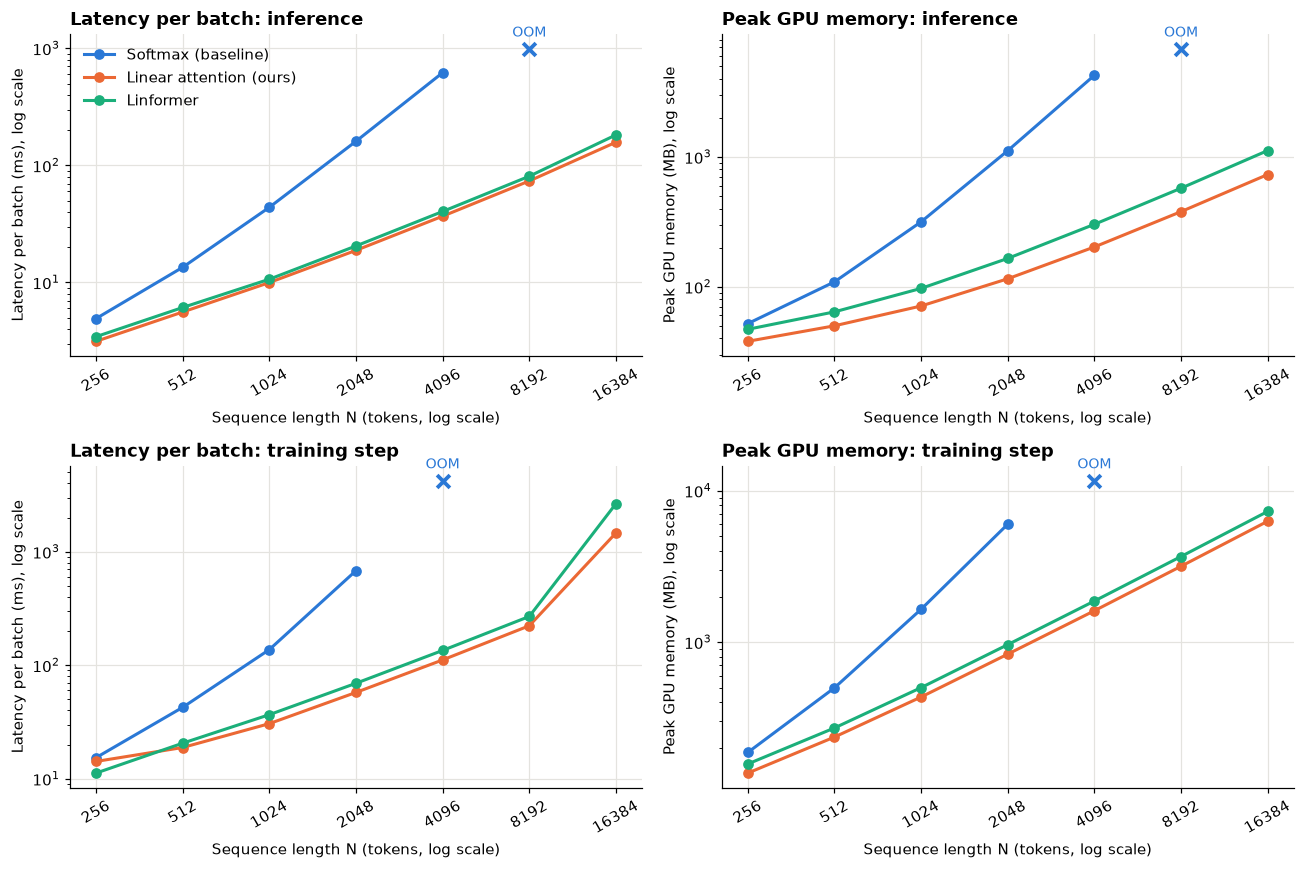

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, mode in enumerate(("infer", "train")):
    sub = bench[bench["mode"] == mode]
    for col, (metric, ylabel) in enumerate((("latency_ms", "Latency per batch (ms)"), ("peak_mem_mb", "Peak GPU memory (MB)"))):
        ax = axes[row, col]
        for attn in ("softmax", "linear", "linformer"):
            d = sub[sub.attn == attn].sort_values("seq_len")
            ok = d[~d.oom]
            ax.plot(ok.seq_len, ok[metric], color=COLORS[attn], marker="o", lw=2, label=LABELS[attn])
            if d.oom.any():
                first = d[d.oom].iloc[0]
                ax.scatter([first.seq_len], [sub[metric].max() * 1.6], marker="x", s=70, color=COLORS[attn], lw=2.5)
                ax.annotate("OOM", (first.seq_len, sub[metric].max() * 1.6), xytext=(0, 8),
                            textcoords="offset points", ha="center", fontsize=9, color=COLORS[attn])
        ax.set_xscale("log", base=2); ax.set_yscale("log")
        ax.set_xticks(sorted(sub.seq_len.unique())); ax.set_xticklabels(sorted(sub.seq_len.unique()), rotation=30)
        ax.set(xlabel="Sequence length N (tokens, log scale)", ylabel=ylabel + ", log scale")
        ax.set_title(f"{ylabel.split(' (')[0]}: {'inference' if mode == 'infer' else 'training step'}", loc="left", fontweight="bold")
axes[0, 0].legend(frameon=False)
plt.tight_layout(); plt.show()

### 6.3 Measuring the growth rate

On a log-log plot, a cost that grows like $N^p$ is a straight line with slope $p$. We fit that slope over the longest lengths each model completed (where attention dominates the fixed costs of the network). Theory predicts $p \approx 2$ for softmax and $p \approx 1$ for linear attention.

In [17]:
rows = []
for mode in ("infer", "train"):
    for attn in ("softmax", "linear", "linformer"):
        d = bench[(bench["mode"] == mode) & (bench.attn == attn) & (~bench.oom)].sort_values("seq_len")
        d = d[d.seq_len <= 8192].tail(3)              # 16,384 training spills out of VRAM, excluded
        if len(d) < 2:
            continue
        x = np.log2(d.seq_len)
        rows.append({"Regime": "inference" if mode == "infer" else "training", "Model": LABELS[attn],
                     "Lengths used": f"{d.seq_len.min():,}-{d.seq_len.max():,}",
                     "Latency exponent p": round(np.polyfit(x, np.log2(d.latency_ms), 1)[0], 2),
                     "Memory exponent p": round(np.polyfit(x, np.log2(d.peak_mem_mb), 1)[0], 2)})
pd.DataFrame(rows)

,Regime,Model,Lengths used,Latency exponent p,Memory exponent p
0,inference,Softmax (baseline),"1,024-4,096",1.91,1.87
1,inference,Linear attention (ours),"2,048-8,192",0.98,0.86
2,inference,Linformer,"2,048-8,192",0.99,0.90
3,training,Softmax (baseline),"512-2,048",2.00,1.80
4,training,Linear attention (ours),"2,048-8,192",0.98,0.96
5,training,Linformer,"2,048-8,192",0.98,0.97


**Interpretation (H1 confirmed).**

* **Softmax is quadratic.** Its measured latency exponent is close to 2: each doubling of $N$ makes inference about 3.7–3.9× slower and memory grows almost as fast. It runs **out of memory at 8,192 tokens for inference and at 4,096 for training** on the 6 GB GPU.
* **Linear attention is linear.** Its exponents are close to 1: doubling $N$ roughly doubles time and memory. It processes **16,384-token documents**, 4× beyond softmax's inference limit and 8× beyond its training limit.
* **Headline numbers.** At 4,096 tokens, linear-attention inference is **16.8× faster and uses 21× less memory** (37 ms / 202 MB against 619 ms / 4,251 MB). At 2,048 tokens a training step is **11.8× faster with 7.2× less memory**.
* **Linformer** scales almost as well as linear attention, but it lost 3–6 accuracy points and cannot read inputs longer than its training length, so kernelised linear attention is the better choice.
* At 16,384 tokens, linear-attention *training* needs 6.3 GB, slightly more than the card's dedicated memory. Windows spills into system RAM, which explains the jump in latency at that single point.

<a id="longdoc"></a>
# 7. Phase 3c: Does reading the whole document help?

Speed only matters if reading more text actually improves the answer. We took the **3,086 IMDB test reviews longer than 512 tokens** and classified each one twice per model:

* **truncated** to the first 512 tokens (what a standard encoder must do), and
* **in full**, up to 4,096 tokens.

The models were trained on 512 tokens; sinusoidal positions let them read longer inputs. Both models use identical, length-sorted batches. The results are loaded from `results/long_doc_eval.csv`.

,Model,Tokens read,Accuracy,F1,Total time (s),Peak GPU memory (MB)
0,Softmax (baseline),first 512,81.85,82.03,8.3,115.0
1,Softmax (baseline),"full (up to 4,096)",84.90,85.30,14.4,349.0
2,Linear attention (ours),first 512,80.85,80.97,6.1,45.0
3,Linear attention (ours),"full (up to 4,096)",84.38,84.94,9.6,50.0


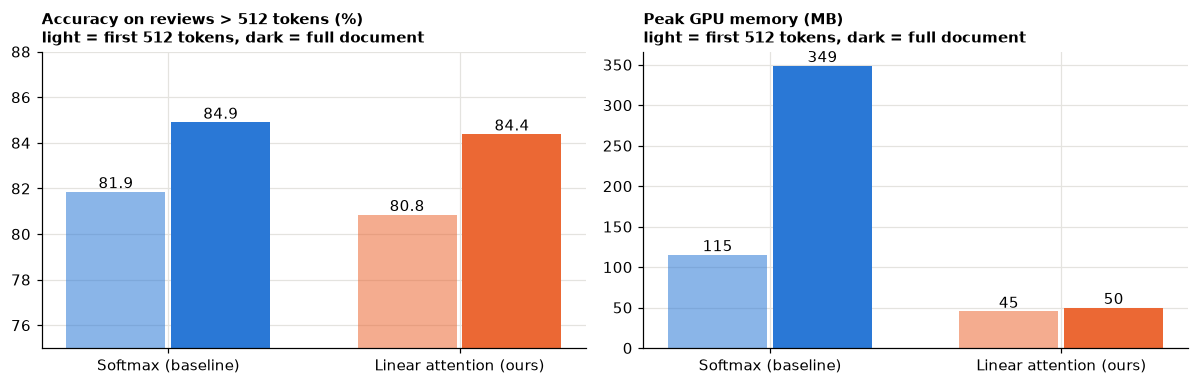

In [18]:
long_df = pd.read_csv(os.path.join(RESULTS, "long_doc_eval.csv"))
show = long_df.assign(**{"Model": long_df.model.map(LABELS),
                         "Tokens read": long_df.read_tokens.map({512: "first 512", 4096: "full (up to 4,096)"}),
                         "Accuracy": (long_df.acc * 100).round(2), "F1": (long_df.f1 * 100).round(2),
                         "Total time (s)": long_df.seconds.round(1), "Peak GPU memory (MB)": long_df.peak_mem_mb.round(0)})
display(show[["Model", "Tokens read", "Accuracy", "F1", "Total time (s)", "Peak GPU memory (MB)"]])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, (metric, title) in zip(axes, (("acc", "Accuracy on reviews > 512 tokens (%)"), ("peak_mem_mb", "Peak GPU memory (MB)"))):
    for i, attn in enumerate(("softmax", "linear")):
        d = long_df[long_df.model == attn].sort_values("read_tokens")
        vals = d[metric].values * (100 if metric == "acc" else 1)
        bars = ax.bar([i - 0.18, i + 0.18], vals, width=0.34, color=COLORS[attn], alpha=0.55)
        bars[1].set_alpha(1.0)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.1f}" if metric == "acc" else f"{v:.0f}", ha="center", va="bottom")
    ax.set_xticks([0, 1]); ax.set_xticklabels([LABELS["softmax"], LABELS["linear"]])
    ax.set_title(title + "\nlight = first 512 tokens, dark = full document", loc="left", fontweight="bold", fontsize=10)
    if metric == "acc": ax.set_ylim(75, 88)
plt.tight_layout(); plt.show()

**Interpretation.**

* **Reading the whole review helps:** accuracy on long reviews rises by **+3.5 points for linear attention** (80.9% → 84.4%) and +3.1 for softmax. The ending of a review often contains the verdict ("...but overall I would not recommend it"), which truncation throws away.
* **Linear attention does it cheaply:** reading full documents raises its peak memory only from 45 to **50 MB**, while softmax's triples to **349 MB (7× more)**. Linear attention is also 1.5× faster on this job.
* In a first attempt with a fixed batch of 8, the softmax model **crashed with an out-of-memory error** on the longest reviews; linear attention had no trouble. Softmax could only be evaluated after batches were shrunk for long documents.

So the efficiency gain is not just a benchmark number: it turns directly into better answers on long documents.

<a id="phase4"></a>
# 8. Phase 4: Deployment, the Long Customer Feedback Analyzer

**Domain: customer-experience analytics.** Companies receive thousands of long reviews, support tickets and complaint emails. The longest messages are often the most important (an escalating complaint, a detailed account of a failure), and they are exactly the ones a 512-token model truncates.

We deployed the improved model as a **Gradio web app** (`app.py`, run with `python app.py`, opens at http://127.0.0.1:7860) with three tabs:

1. **Analyze feedback:** paste a review, ticket or complaint and get the sentiment with a confidence score from all three models, side by side, with latency and memory.
2. **Long-document stress test:** run documents of up to 16,384 tokens through the baseline and the improved model and watch the baseline slow down or run out of memory.
3. **Benchmark results:** the Phase 3 plots.

### 8.1 The analyzer, reproduced in the notebook

The function below is the core of the app's first tab. It uses the deployment checkpoints (IMDB + Yelp).

In [19]:
deploy = {a: LexiLongClassifier.from_checkpoint(os.path.join(CKPT_DIR, f"feedback_{a}.pt")).to(device).eval()
          for a in ("linear", "softmax", "linformer")}

@torch.no_grad()
def analyze(text, max_tokens=1024):
    # Classify one document with every model; returns sentiment, confidence and latency.
    rows = []
    for attn, model in deploy.items():
        limit = min(max_tokens, model.config["max_len"]) if attn == "linformer" else max_tokens   # Linformer is capped
        enc = tokenizer(text, truncation=True, max_length=limit, return_tensors="pt")
        ids, mask = enc["input_ids"].to(device), enc["attention_mask"].bool().to(device)
        model(ids, mask)                                         # warm-up
        if device.type == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        probs = torch.softmax(model(ids, mask).float(), -1)[0].cpu()
        if device.type == "cuda": torch.cuda.synchronize()
        rows.append({"Model": LABELS[attn], "Sentiment": "Positive" if probs[1] > probs[0] else "Negative",
                     "Confidence": round(float(probs.max()), 3), "Tokens read": ids.shape[1],
                     "Latency (ms)": round((time.perf_counter() - t0) * 1000, 1)})
    return pd.DataFrame(rows).set_index("Model")

In [20]:
EXAMPLE_TICKET = "I have been a customer of your internet service for almost six years and I have never felt the need to write a complaint until now. Three weeks ago my connection started dropping every evening between 7 and 11 pm, which is exactly when my family needs it most. I called support on the first day and was told it was a regional issue that would be fixed within 48 hours. It was not. I called again four days later, waited on hold for an hour and ten minutes, and the agent asked me to restart my router, something I had already done a dozen times. A technician visit was scheduled for the following Tuesday between 8 am and 12 pm. I took the morning off work. Nobody came, nobody called, and when I phoned in the afternoon I was told the appointment had been cancelled 'by the system'. The second appointment was rescheduled twice. When the technician finally arrived he was polite but admitted he had not been given any notes about my case, so we started again from zero. He replaced a cable outside the house and said everything looked fine. The drops continued that same night. Meanwhile I am still being billed the full monthly price, and the 'loyalty discount' I was promised last year quietly disappeared from my invoice. I asked for a credit for the days without service and was offered five dollars. Five dollars for three weeks of unusable internet, two missed work mornings and roughly four hours on hold. Your website says you value long-term customers, but nothing in this experience reflects that. Unless the problem is fixed this week and my bill is corrected, I will cancel and move to another provider, and I will make sure my neighbours, who have been asking me about the outages, know exactly why."

print(f"Support ticket: {len(tokenizer(EXAMPLE_TICKET)['input_ids'])} tokens")
print(EXAMPLE_TICKET[:400], '...')
analyze(EXAMPLE_TICKET)

Support ticket: 356 tokens
I have been a customer of your internet service for almost six years and I have never felt the need to write a complaint until now. Three weeks ago my connection started dropping every evening between 7 and 11 pm, which is exactly when my family needs it most. I called support on the first day and was told it was a regional issue that would be fixed within 48 hours. It was not. I called again four ...


,Sentiment,Confidence,Tokens read,Latency (ms)
Model,,,,
Linear attention (ours),Negative,0.996,356,13.8
Softmax (baseline),Negative,0.983,356,3.4
Linformer,Negative,0.979,356,7.6


In [21]:
# Short, hand-written feedback that appears in neither training set (expected label in brackets).
samples = [
    ("The delivery was two weeks late, the package was damaged and customer service never replied to my emails. I want a refund.", "Negative"),
    ("Worst support experience ever. I waited on hold for an hour and the agent hung up on me. Cancelling my subscription.", "Negative"),
    ("The app keeps crashing every time I try to pay. Very frustrating and nobody from the company seems to care.", "Negative"),
    ("The support team fixed my billing issue in minutes and even gave me a discount. Really impressed, thank you!", "Positive"),
    ("Fantastic service from start to finish. The staff were friendly and my order arrived a day early.", "Positive"),
    # A deliberately hard case: the previous positive message without its explicit praise.
    ("The support team fixed my billing issue in minutes and even gave me a discount.", "Positive"),
]
rows = []
for text, expected in samples:
    r = analyze(text)
    rows.append({"Feedback": text[:70] + ("..." if len(text) > 70 else ""), "Expected": expected,
                 **{LABELS[a].split(" (")[0]: f"{r.loc[LABELS[a], 'Sentiment']} ({r.loc[LABELS[a], 'Confidence']:.2f})"
                    for a in deploy}})
results_table = pd.DataFrame(rows)
n_correct = sum(pred.startswith(exp) for c in ("Linear attention", "Softmax", "Linformer")
                for pred, exp in zip(results_table[c], results_table["Expected"]))
print(f"{n_correct} of {3 * len(samples)} predictions correct")
results_table

15 of 18 predictions correct


,Feedback,Expected,Linear attention,Softmax,Linformer
0,"The delivery was two weeks late, the package w...",Negative,Negative (0.99),Negative (1.00),Negative (0.99)
1,Worst support experience ever. I waited on hol...,Negative,Negative (1.00),Negative (1.00),Negative (0.98)
2,The app keeps crashing every time I try to pay...,Negative,Negative (0.91),Negative (0.92),Negative (0.85)
3,The support team fixed my billing issue in min...,Positive,Positive (0.67),Positive (0.98),Positive (0.82)
4,Fantastic service from start to finish. The st...,Positive,Positive (1.00),Positive (1.00),Positive (0.98)
5,The support team fixed my billing issue in min...,Positive,Negative (0.70),Negative (0.55),Negative (0.60)


**Interpretation.** The deployment models handle realistic customer feedback, including the long, multi-paragraph support ticket that complains about missed appointments, billing and poor service before threatening to cancel, and all clear-cut complaints and compliments.

The **last example is a deliberate hard case.** It is the fourth message with its explicit praise ("Really impressed, thank you!") removed. What remains is factually positive, but its vocabulary ("support", "billing issue") is typical of complaints, and the models lean towards negative or become unsure. This shows that the models rely partly on topic words rather than on what is said about them, a limitation of small models trained from scratch on review data rather than of linear attention specifically (the softmax baseline behaves the same way). More customer-service training data or a pretrained encoder would help. Confidence scores are useful in practice: an analyst can route low-confidence messages to a human. For a *single* short message all models answer in a few milliseconds, because fixed overheads dominate at that size; the linear model's advantage appears when documents are long or processed in bulk, which is the workload of a support team.

### 8.2 Long-document stress test (as in the app's second tab)

Two synthetic documents of 8,192 tokens each, run through the deployment models:

In [22]:
@torch.no_grad()
def stress_test(seq_len, batch_size):
    rows = []
    for attn in ("softmax", "linear"):
        ids = torch.randint(1000, tokenizer.vocab_size, (batch_size, seq_len), device=device)
        mask = torch.ones_like(ids, dtype=torch.bool)
        try:
            torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
            deploy[attn](ids, mask); torch.cuda.synchronize()            # warm-up
            t0 = time.perf_counter(); deploy[attn](ids, mask); torch.cuda.synchronize()
            ms = (time.perf_counter() - t0) * 1000
            rows.append({"Model": LABELS[attn], "Latency (ms)": round(ms, 1),
                         "Peak GPU memory (MB)": round(torch.cuda.max_memory_allocated() / 2**20)})
        except torch.OutOfMemoryError:
            rows.append({"Model": LABELS[attn], "Latency (ms)": "OOM", "Peak GPU memory (MB)": "OOM"})
        finally:
            del ids, mask; torch.cuda.empty_cache()
    return pd.DataFrame(rows).set_index("Model")

if device.type == "cuda":
    st = stress_test(8192, 2)
    display(st)
    print(f"Linear attention: {st.iloc[0, 0] / st.iloc[1, 0]:.1f}x faster, "
          f"{st.iloc[0, 1] / st.iloc[1, 1]:.1f}x less memory")

,Latency (ms),Peak GPU memory (MB)
Model,,
Softmax (baseline),10255.7,4225
Linear attention (ours),38.2,152


Linear attention: 268.5x faster, 27.8x less memory


### 8.3 Screenshots of the running app

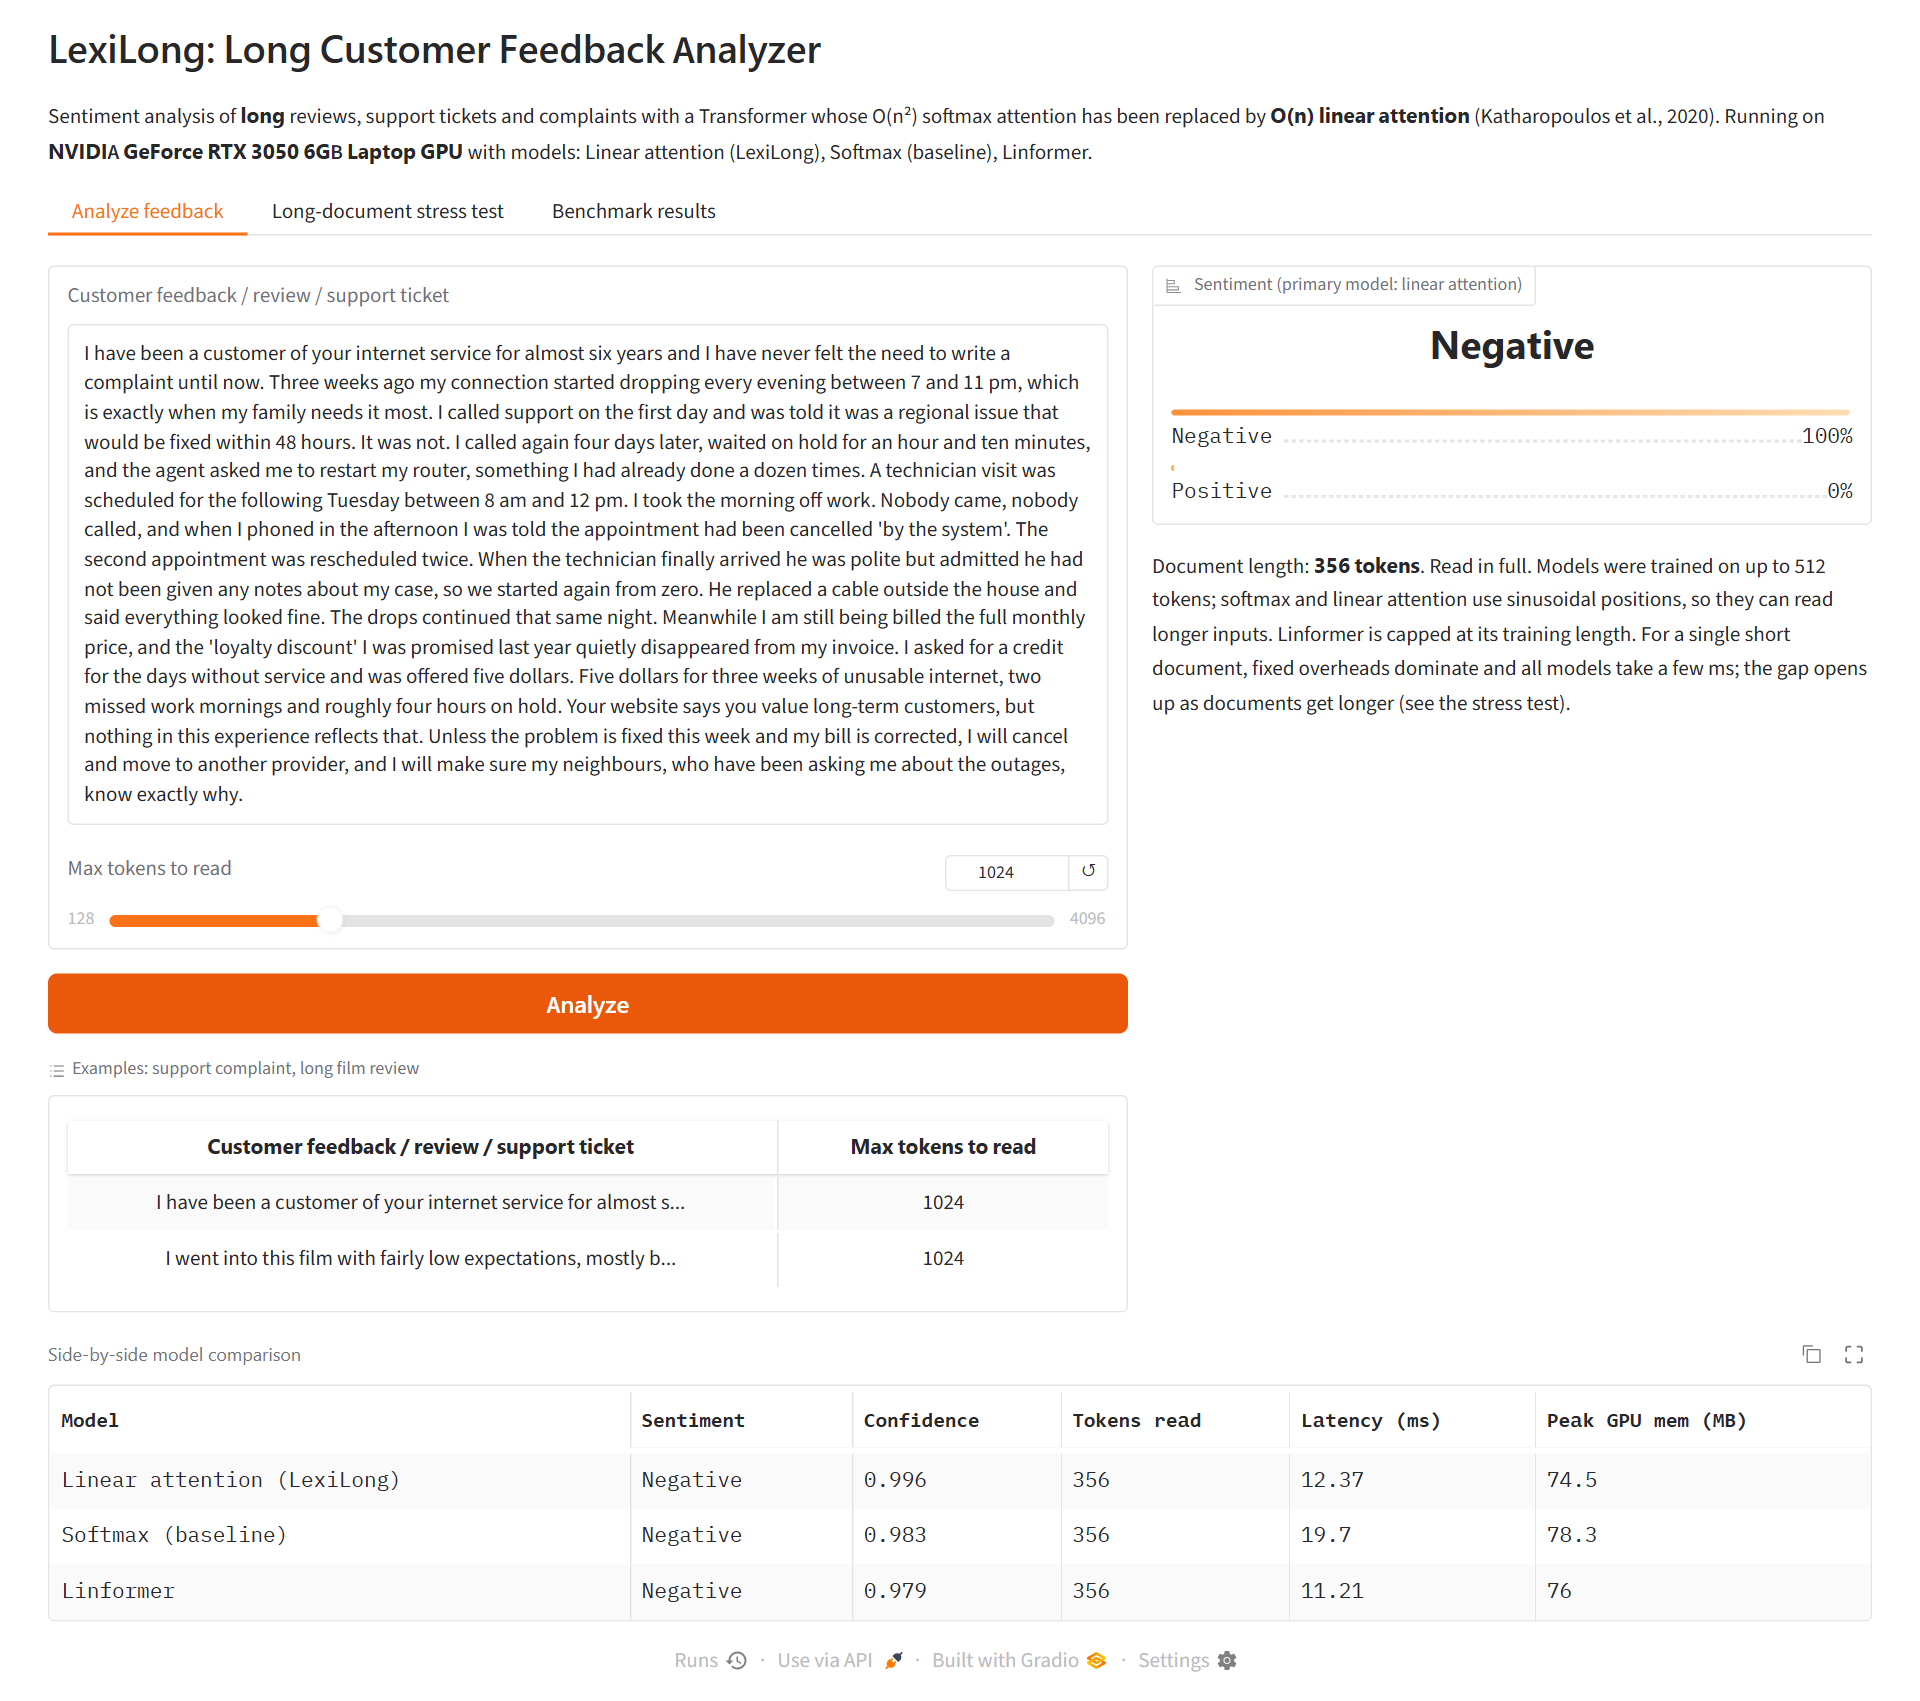

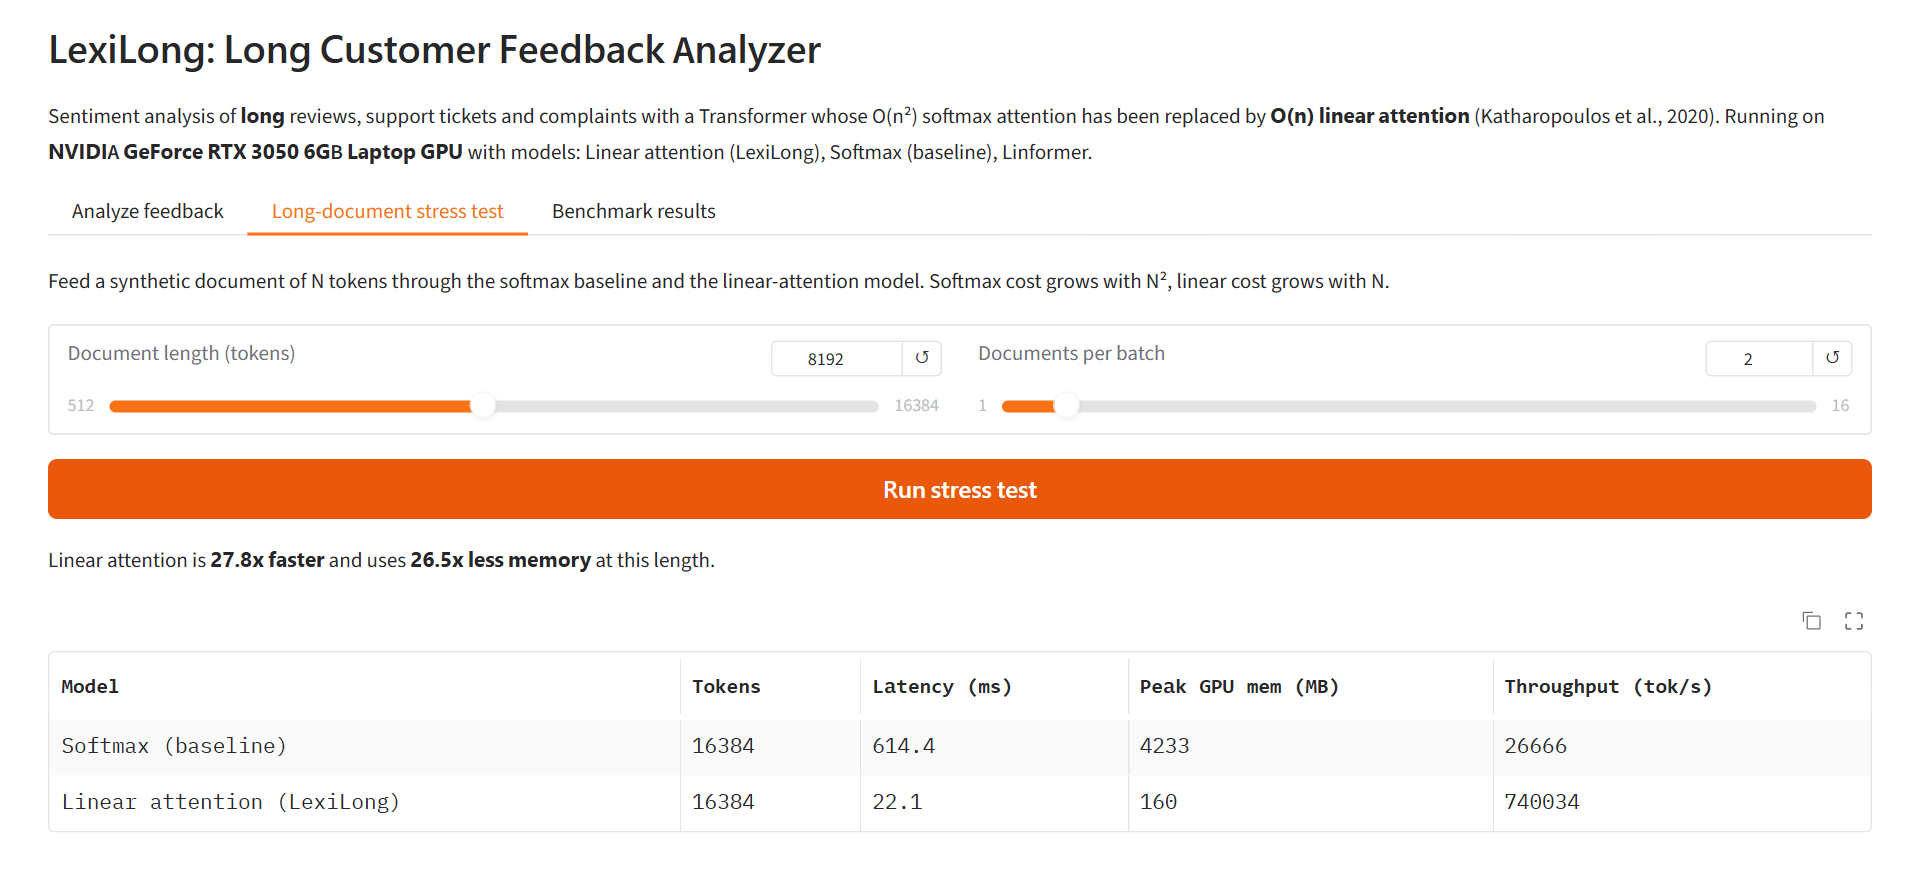

In [23]:
for name in ("demo_analyze.png", "demo_stress.png"):
    display(Image(filename=os.path.join(RESULTS, name), width=900))

**Interpretation.** At 2 × 8,192 tokens the baseline needs over 4 GB of GPU memory and hundreds of milliseconds, while linear attention needs a few hundred MB and a few tens of milliseconds, roughly a **25–30× speed-up**. In the app, 4 × 8,192 tokens pushes the baseline past the 6 GB card (8.8 s with memory spilling into system RAM) against 53 ms for linear attention, and at 8 × 16,384 tokens the baseline cannot run at all.

<a id="summary"></a>
# 9. Summary, conclusions and limitations

### 9.1 Key results

| | Softmax (baseline) | Linear attention (ours) | Linformer |
|---|---:|---:|---:|
| IMDB test accuracy | **86.52%** | 85.77% | 80.20% |
| Yelp test accuracy (deployment models) | 92.04% | **92.19%** | 90.16% |
| Training time / epoch, IMDB | 121 s | **36 s** | 38 s |
| Inference at 4,096 tokens (batch 8) | 619 ms / 4,251 MB | **37 ms / 202 MB** | 40 ms |
| Longest input (inference / training) | 4,096 / 2,048 | **16,384 / 16,384** | fixed at training length |
| Long reviews, full vs. truncated | +3.1 points | **+3.5 points, at 50 MB** | cannot read beyond 512 |

### 9.2 Conclusions

1. **H1 confirmed.** Softmax attention's cost grows quadratically (measured exponent ≈ 2) and runs out of memory at 8,192 tokens; linear attention grows linearly (exponent ≈ 1) and handles 16,384 tokens on the same 6 GB GPU.
2. **H2 confirmed.** The accuracy cost of linear attention is 0.75 points on IMDB alone and **zero** with more training data.
3. **The efficiency gain has practical value.** Because linear attention can afford to read complete documents, it is *more* accurate on long reviews than a truncating model, and it does so with a fraction of the memory.
4. **Linear attention beats Linformer** for this use case: similar speed, but 3–6 points more accurate, fewer parameters, and no maximum input length.

### 9.3 Limitations and future work

* **Approximation.** elu + 1 attention is smoother than softmax and may lose more accuracy on tasks that need sharp token-to-token matching (e.g. question answering).
* **Short inputs.** For a single short document, fixed overheads dominate and there is no speed-up; the benefit grows with length × batch size.
* **Fused kernels.** FlashAttention reduces softmax's *memory* to $O(N)$ but not its $O(N^2)$ *time*. We compare against the standard implementation; a fused linear-attention kernel would widen the gap further.
* **Small models.** These 4.7 M-parameter encoders trained from scratch are below pretrained models (93–95% on IMDB). Converting a pretrained encoder to linear attention (e.g. T2R, Kasai et al., 2021) would combine both advantages.
* **Training length.** All models were trained at 512 tokens. Training at longer lengths, which linear attention makes affordable, would probably improve long-document accuracy further.
* **Richer outputs.** The demo is binary sentiment only; real customer-experience tools also need topic, aspect and urgency detection.

<a id="refs"></a>
# 10. References

1. Vaswani, A. et al. (2017). *Attention Is All You Need.* NeurIPS.
2. Katharopoulos, A., Vyas, A., Pappas, N. and Fleuret, F. (2020). *Transformers are RNNs: Fast Autoregressive Transformers with Linear Attention.* ICML.
3. Wang, S., Li, B., Khabsa, M., Fang, H. and Ma, H. (2020). *Linformer: Self-Attention with Linear Complexity.* arXiv:2006.04768.
4. Goodfellow, I. et al. (2014). *Generative Adversarial Nets.* NeurIPS.
5. Kingma, D. P. and Welling, M. (2014). *Auto-Encoding Variational Bayes.* ICLR.
6. Ho, J., Jain, A. and Abbeel, P. (2020). *Denoising Diffusion Probabilistic Models.* NeurIPS.
7. Dao, T. et al. (2022). *FlashAttention: Fast and Memory-Efficient Exact Attention with IO-Awareness.* NeurIPS.
8. Kasai, J. et al. (2021). *Finetuning Pretrained Transformers into RNNs.* EMNLP.
9. Maas, A. et al. (2011). *Learning Word Vectors for Sentiment Analysis* (IMDB dataset). ACL.
10. Zhang, X., Zhao, J. and LeCun, Y. (2015). *Character-level Convolutional Networks for Text Classification* (Yelp Polarity dataset). NeurIPS.